# Бустинг и интерпретация увольнений сотрудников
Вариант 14, IBM HR Employee Attrition. Сравним три бустинга, настроим победителя, объясним прогнозы и проверим стекинг и обработку дисбаланса. Отложенные 20% используются только после выбора итогового подхода по обучающей кросс-валидации.

In [1]:
from pathlib import Path
import os, time, warnings
os.environ['OMP_NUM_THREADS'] = '2'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, ConfusionMatrixDisplay
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import ADASYN
import optuna, shap, joblib
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message='The `probability` parameter was deprecated', category=FutureWarning)
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
plt.rcParams.update({'figure.figsize': (9, 5), 'figure.dpi': 110})
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


C:\Users\t-pud\AppData\Local\Temp\prod-me-boosting-interpretability-20261023\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Данные и границы эксперимента
Источник: [IBM HR Analytics Employee Attrition](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset). Исходный CSV хранится без изменений в `data/raw` под DVC. Убираем цель, идентификатор EmployeeNumber и константы EmployeeCount, Over18, StandardHours. Отсутствующие значения заполняются внутри каждого обучающего фолда; категории кодируются one-hot, числовые признаки масштабируются. Это также обеспечивает сопоставимые расстояния для SVC и ADASYN.

In [2]:
raw = pd.read_csv(ROOT / 'data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv')
y = raw['Attrition'].eq('Yes').astype(int)
X = raw.drop(columns=['Attrition', 'EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
num = X_train.select_dtypes(include='number').columns.tolist()
cat = X_train.select_dtypes(exclude='number').columns.tolist()
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num),
    ('category', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)
], verbose_feature_names_out=False)
def pipeline(model):
    return Pipeline([('preprocess', clone(preprocessor)), ('model', model)])
assert len(raw) == 1470 and X_train.index.intersection(X_test.index).empty
assert not {'Attrition', 'EmployeeNumber', 'EmployeeCount', 'Over18', 'StandardHours'} & set(X.columns)
display(pd.DataFrame({'rows': [len(raw), len(X_train), len(X_test)], 'positive_rate': [y.mean(), y_train.mean(), y_test.mean()]}, index=['source', 'train', 'test']))
print('Missing values:', X.isna().sum().sum(), '; features:', X.shape[1])


,rows,positive_rate
source,1470,0.161224
train,1176,0.161565
test,294,0.159864


Missing values: 0 ; features: 30


## Три библиотеки с параметрами по умолчанию
Меняются только seed, число потоков и служебная подробность вывода. Для CatBoost отключена запись служебных файлов. Статистические параметры оставлены стандартными. Выбор делаем по среднему ROC-AUC пяти обучающих фолдов; время показывает стоимость полного CV и среднее время fit.

In [3]:
defaults = {
    'XGBoost': XGBClassifier(random_state=SEED, n_jobs=2, verbosity=0),
    'LightGBM': LGBMClassifier(random_state=SEED, n_jobs=2, verbosity=-1),
    'CatBoost': CatBoostClassifier(random_seed=SEED, thread_count=2, verbose=False, allow_writing_files=False)
}
scoring = {'ROC_AUC': 'roc_auc', 'PR_AUC': 'average_precision', 'F1': 'f1'}
rows = []
candidates = {}
def evaluate(name, estimator):
    start = time.perf_counter()
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1, error_score='raise')
    row = {'approach': name, 'ROC_AUC': scores['test_ROC_AUC'].mean(), 'ROC_AUC_std': scores['test_ROC_AUC'].std(), 'PR_AUC': scores['test_PR_AUC'].mean(), 'F1': scores['test_F1'].mean(), 'fit_seconds_mean': scores['fit_time'].mean(), 'CV_seconds': time.perf_counter()-start}
    rows.append(row); candidates[name] = estimator
    return row
for name, model in defaults.items():
    print(name, evaluate(name, pipeline(model)), flush=True)
baseline_table = pd.DataFrame(rows).set_index('approach')
display(baseline_table.round(4))
winner = baseline_table['ROC_AUC'].idxmax()
print('Библиотека для Optuna:', winner)


XGBoost {'approach': 'XGBoost', 'ROC_AUC': np.float64(0.7997204208799186), 'ROC_AUC_std': np.float64(0.045204662499608896), 'PR_AUC': np.float64(0.5616772434453371), 'F1': np.float64(0.45047153864799017), 'fit_seconds_mean': np.float64(0.3100132465362549), 'CV_seconds': 1.6404541000083555}


LightGBM {'approach': 'LightGBM', 'ROC_AUC': np.float64(0.8047915705276113), 'ROC_AUC_std': np.float64(0.0314773273327742), 'PR_AUC': np.float64(0.565967943427437), 'F1': np.float64(0.42669276814829377), 'fit_seconds_mean': np.float64(0.06593127250671386), 'CV_seconds': 0.4343766000092728}


CatBoost {'approach': 'CatBoost', 'ROC_AUC': np.float64(0.8229379015913881), 'ROC_AUC_std': np.float64(0.03112564550051849), 'PR_AUC': np.float64(0.635408920615048), 'F1': np.float64(0.401659325619012), 'fit_seconds_mean': np.float64(4.2760901927948), 'CV_seconds': 21.60180570000375}


,ROC_AUC,ROC_AUC_std,PR_AUC,F1,fit_seconds_mean,CV_seconds
approach,,,,,,
XGBoost,0.7997,0.0452,0.5617,0.4505,0.3100,1.6405
LightGBM,0.8048,0.0315,0.5660,0.4267,0.0659,0.4344
CatBoost,0.8229,0.0311,0.6354,0.4017,4.2761,21.6018


Библиотека для Optuna: CatBoost


## Optuna: 50 испытаний на тех же пяти фолдах
TPE имеет фиксированный seed. Пространство поиска ограничено, чтобы эксперимент был воспроизводим на CPU. Test не участвует в подборе. Средний CV победителя после поиска имеет оптимистическое смещение; независимую оценку даст только финальный holdout.

Best CV ROC-AUC: 0.8352459945433495 
Parameters: {'learning_rate': 0.039357542550924884, 'max_depth': 4, 'iterations': 200, 'l2_leaf_reg': 2.560308986679964}


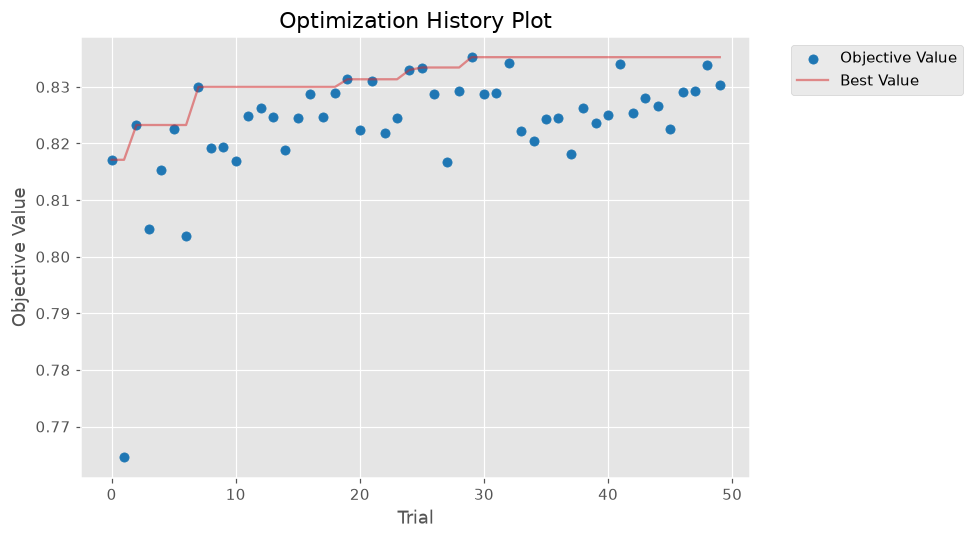

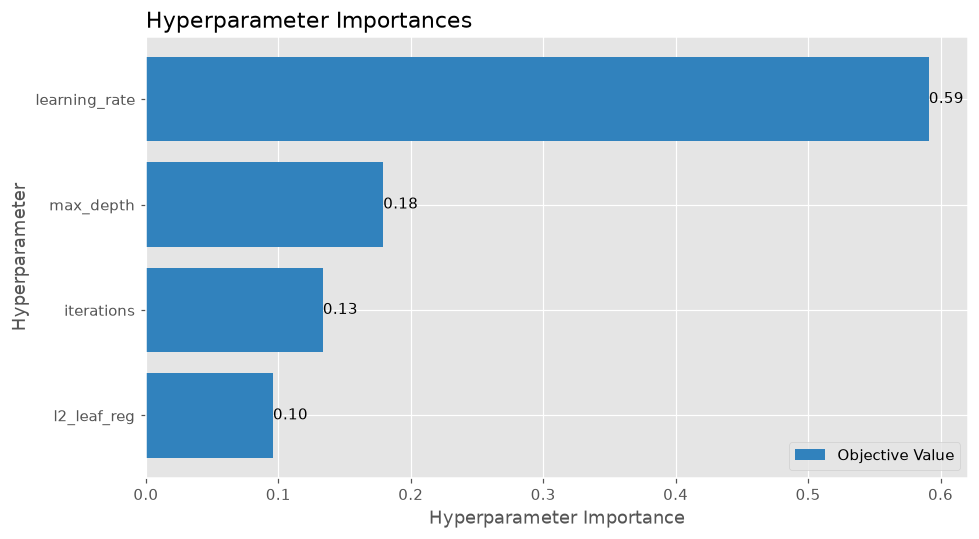

,ROC_AUC,ROC_AUC_std,PR_AUC,F1,fit_seconds_mean,CV_seconds
approach,,,,,,
XGBoost,0.7997,0.0452,0.5617,0.4505,0.3100,1.6405
LightGBM,0.8048,0.0315,0.5660,0.4267,0.0659,0.4344
CatBoost,0.8229,0.0311,0.6354,0.4017,4.2761,21.6018
Optimized,0.8352,0.0295,0.6467,0.4265,0.2144,1.1613


In [4]:
def make_model(params=None, weighted=False):
    params = {} if params is None else dict(params)
    if winner == 'XGBoost':
        return XGBClassifier(random_state=SEED, n_jobs=2, verbosity=0, **params)
    if winner == 'LightGBM':
        return LGBMClassifier(random_state=SEED, n_jobs=2, verbosity=-1, **params)
    return CatBoostClassifier(random_seed=SEED, thread_count=2, verbose=False, allow_writing_files=False, **params)
def objective(trial):
    params = {'learning_rate': trial.suggest_float('learning_rate', .015, .25, log=True),
              'max_depth': trial.suggest_int('max_depth', 2, 7)}
    if winner == 'CatBoost':
        params['iterations'] = trial.suggest_int('iterations', 50, 200, step=25)
        params['l2_leaf_reg'] = trial.suggest_float('l2_leaf_reg', .1, 20, log=True)
    else:
        params['n_estimators'] = trial.suggest_int('n_estimators', 50, 200, step=25)
        params['reg_lambda'] = trial.suggest_float('reg_lambda', .1, 20, log=True)
        if winner == 'LightGBM':
            params['num_leaves'] = trial.suggest_int('num_leaves', 4, 31)
    return cross_val_score(pipeline(make_model(params)), X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1, error_score='raise').mean()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=50)
assert len(study.trials) == 50 and all(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
print('Best CV ROC-AUC:', study.best_value, '\nParameters:', study.best_params)
optuna.visualization.matplotlib.plot_optimization_history(study)
plt.tight_layout(); plt.show()
optuna.visualization.matplotlib.plot_param_importances(study)
plt.tight_layout(); plt.show()
optimized = pipeline(make_model(study.best_params))
evaluate('Optimized', optimized)
display(pd.DataFrame(rows).set_index('approach').round(4))


## Объяснение оптимизированного бустинга
SHAP рассчитывается для объектов из train после обучения на train. Имена сохраняются после преобразования; знаки показывают вклад в прогноз увольнения, а не причинное влияние. Для двух наиболее важных признаков строим dependence; два первых объекта обучающей выборки выбраны заранее для локальных объяснений.

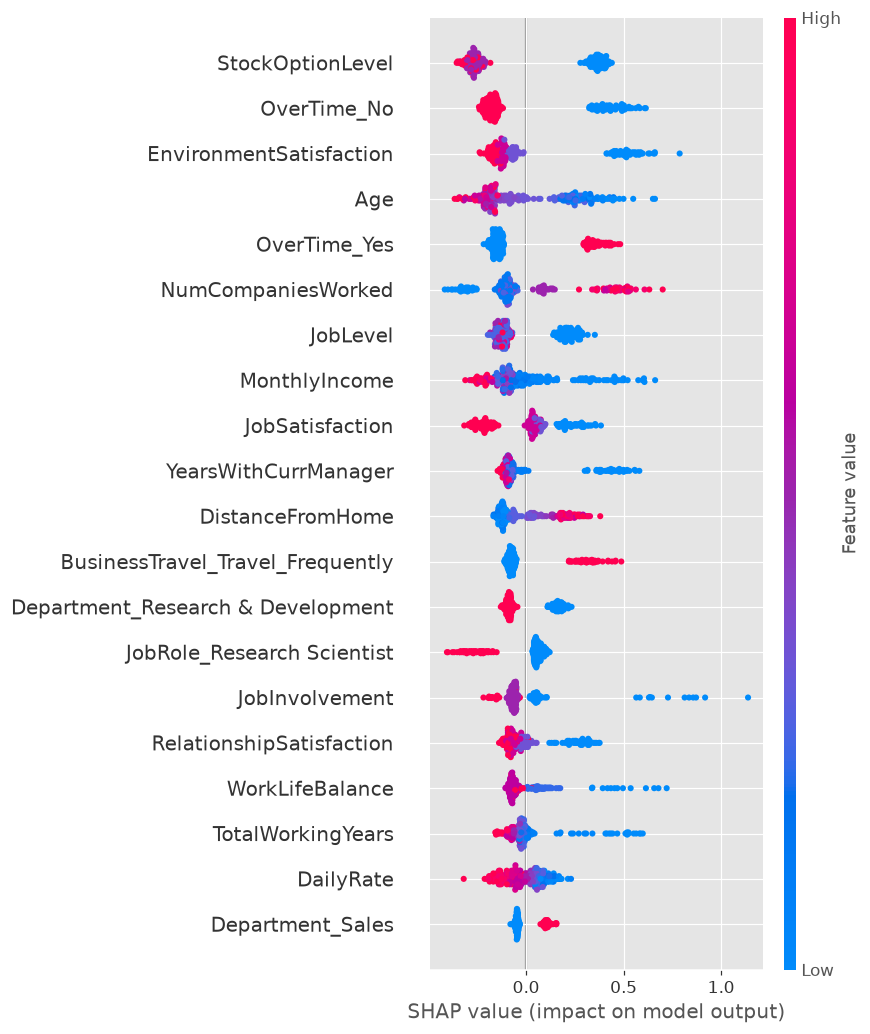

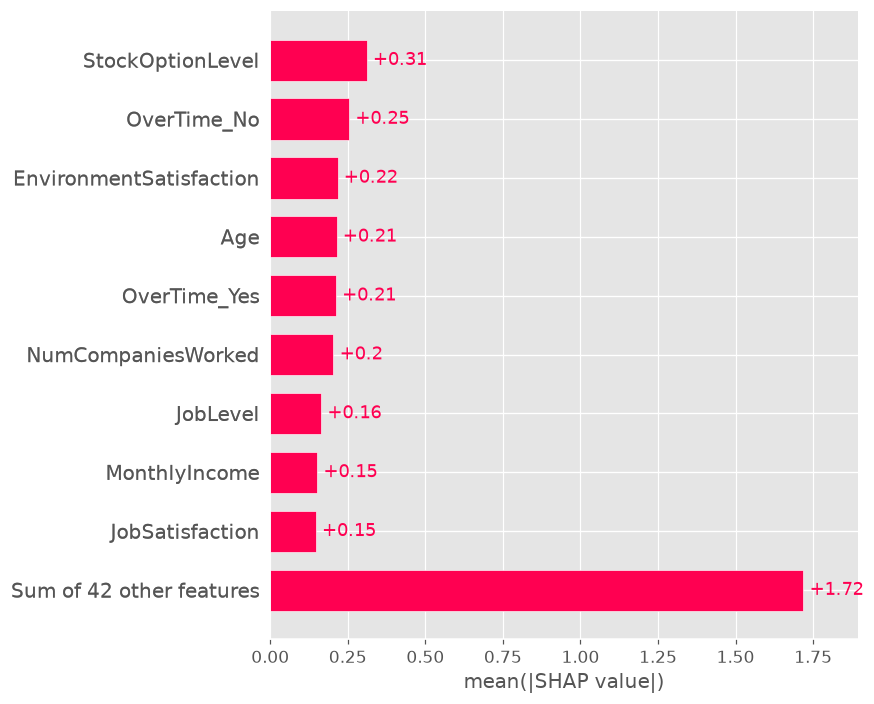

,mean_abs_SHAP
StockOptionLevel,0.310837
OverTime_No,0.254239
EnvironmentSatisfaction,0.216912
Age,0.213770
OverTime_Yes,0.211592
NumCompaniesWorked,0.203669
JobLevel,0.164063
MonthlyIncome,0.151264
JobSatisfaction,0.146609
YearsWithCurrManager,0.146065


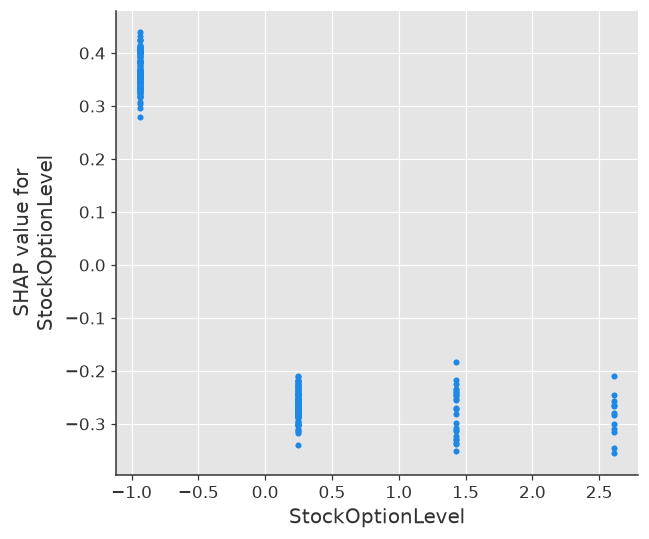

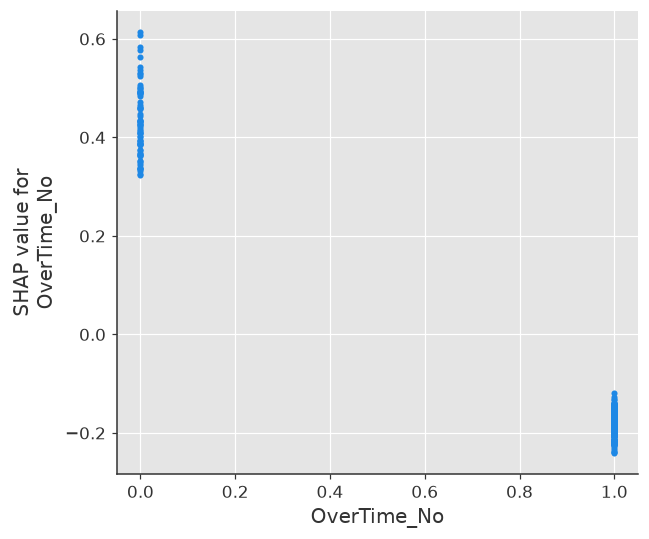

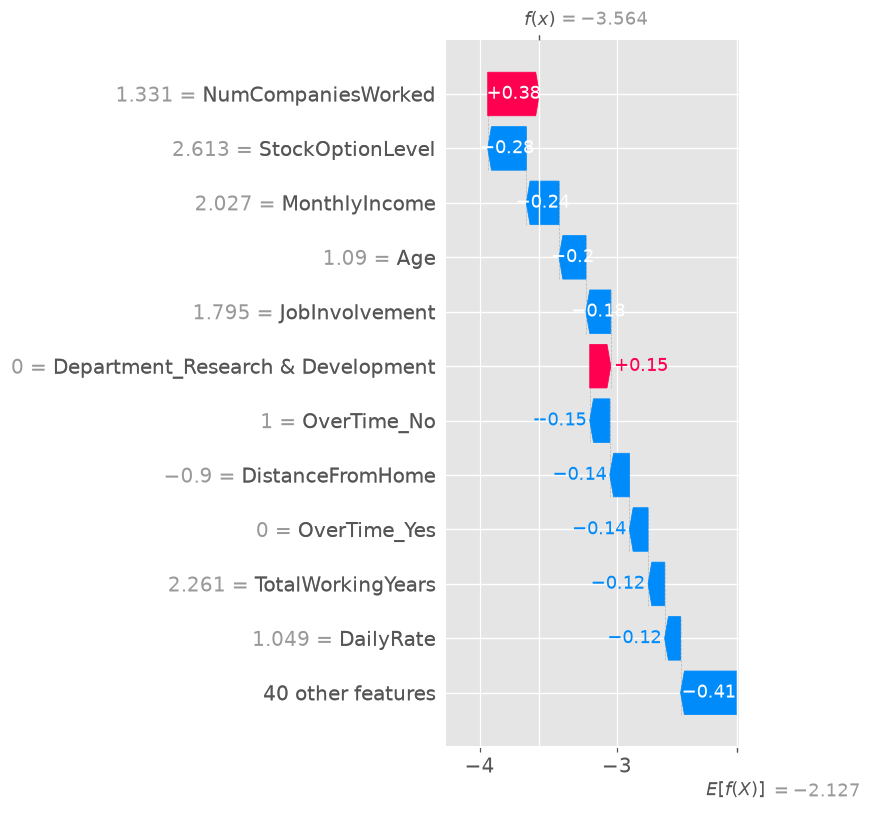

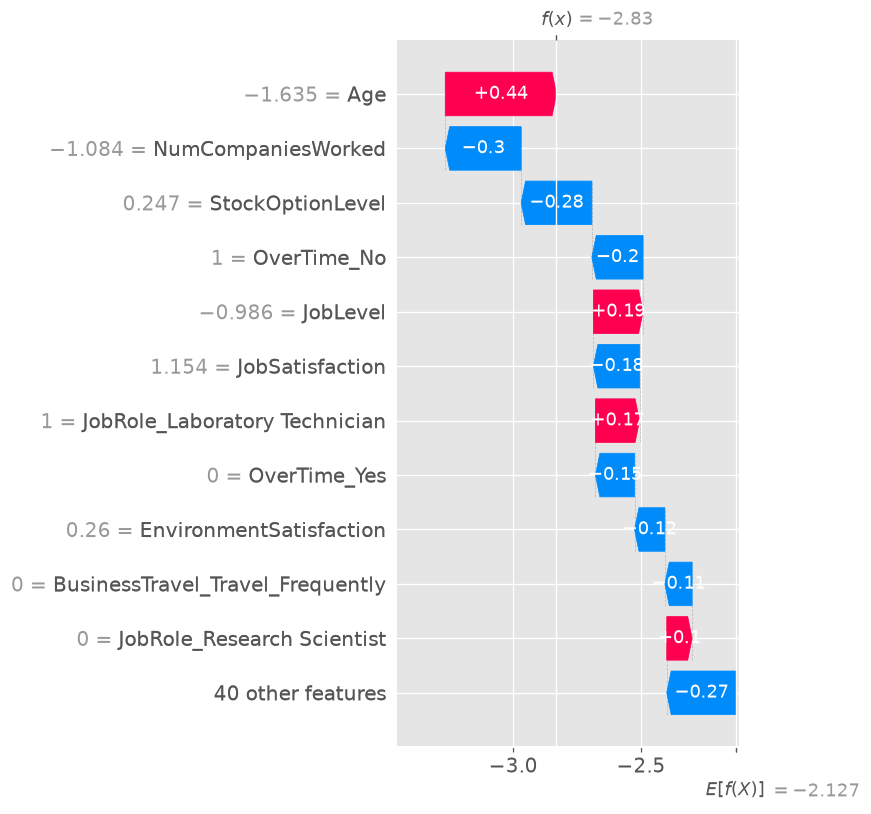

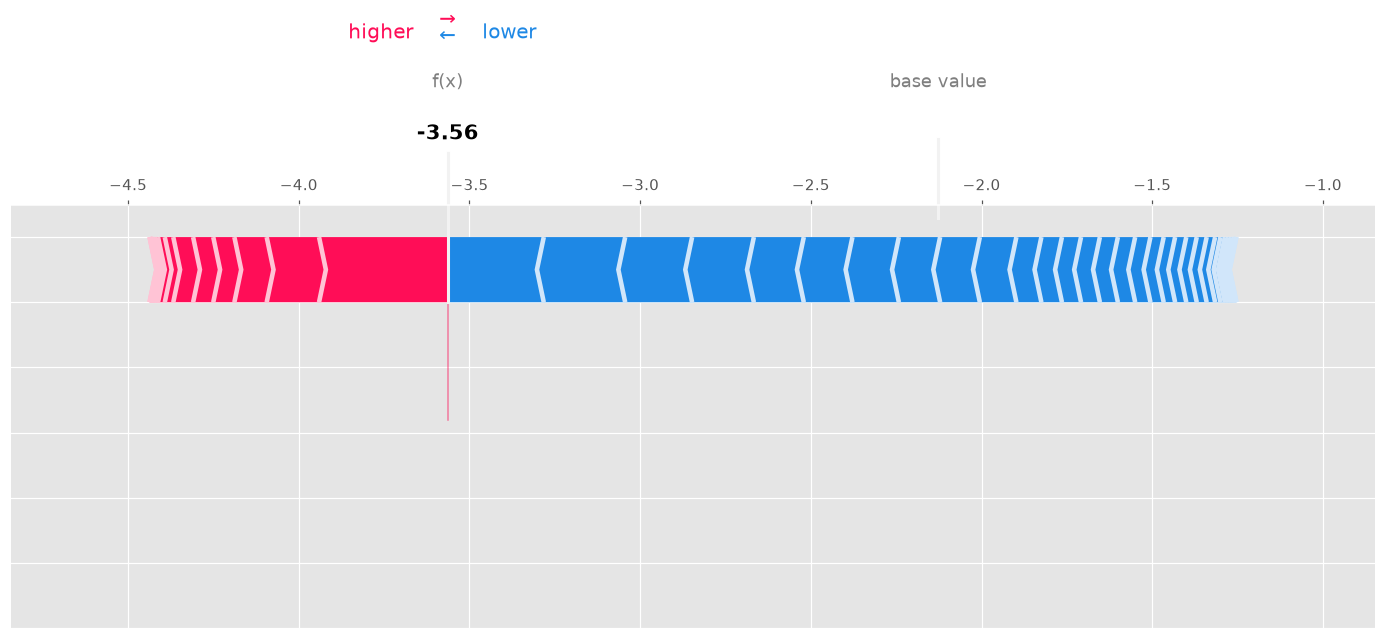

Два лидера SHAP: StockOptionLevel, OverTime_No


,feature,split_transformed_value,SHAP_low,SHAP_high
0,StockOptionLevel,0.2474,0.0517,-0.2799
1,EnvironmentSatisfaction,0.2602,0.1010,-0.1693
2,Age,-0.1088,0.1591,-0.2048
3,OverTime_Yes,0.0000,-0.1506,0.3595


Положительный средний SHAP повышает оценку увольнения, отрицательный снижает; сравнение групп описывает модель, а не причинность.
Статический force показывает полную сумму вкладов; интерактивный HTML ниже сохраняет все подписи и значения.
Полные подписи и значения force: reports/attrition_force.html (интерактивный HTML).


In [5]:
optimized.fit(X_train, y_train)
transformed = pd.DataFrame(optimized.named_steps['preprocess'].transform(X_train), columns=optimized.named_steps['preprocess'].get_feature_names_out(), index=X_train.index)
explain_data = transformed.sample(n=min(250, len(transformed)), random_state=SEED)
explainer = shap.TreeExplainer(optimized.named_steps['model'])
explanation = explainer(explain_data)
if explanation.values.ndim == 3:
    explanation = explanation[:, :, 1]
assert explanation.values.shape == explain_data.shape
shap.summary_plot(explanation.values, explain_data, show=False)
plt.tight_layout(); plt.show()
shap.plots.bar(explanation, show=False)
plt.tight_layout(); plt.show()
importance = pd.Series(np.abs(explanation.values).mean(axis=0), index=explain_data.columns).sort_values(ascending=False)
display(importance.head(10).rename('mean_abs_SHAP').to_frame())
for feature in importance.head(2).index:
    shap.dependence_plot(feature, explanation.values, explain_data, interaction_index=None, show=False)
    plt.tight_layout(); plt.show()
local = explainer(transformed.iloc[:2])
if local.values.ndim == 3:
    local = local[:, :, 1]
for i in range(2):
    shap.plots.waterfall(local[i], max_display=12, show=False)
    plt.tight_layout(); plt.show()
shap.plots.force(local[0], matplotlib=True, show=False, figsize=(16, 5), contribution_threshold=.2, text_rotation=25)
plt.show()
print('Два лидера SHAP:', ', '.join(importance.head(2).index))

patterns = []
for feature in importance.head(5).index:
    j = explain_data.columns.get_loc(feature)
    values = explain_data[feature]
    cut = values.median()
    high = values > cut
    if high.any() and (~high).any():
        patterns.append({'feature': feature, 'split_transformed_value': cut, 'SHAP_low': explanation.values[~high, j].mean(), 'SHAP_high': explanation.values[high, j].mean()})
display(pd.DataFrame(patterns).round(4))
print('Положительный средний SHAP повышает оценку увольнения, отрицательный снижает; сравнение групп описывает модель, а не причинность.')

print('Статический force показывает полную сумму вкладов; интерактивный HTML ниже сохраняет все подписи и значения.')

(ROOT / 'reports').mkdir(exist_ok=True)
shap.save_html(str(ROOT / 'reports/attrition_force.html'), shap.plots.force(local[0]))
print('Полные подписи и значения force: reports/attrition_force.html (интерактивный HTML).')


## Стекинг и дисбаланс
В стекинге LightGBM, RandomForest и SVC(probability=True) имеют собственные pipeline: внутренние OOF-прогнозы получаются без обучения преобразований на валидационном фолде. Мета-модель — логистическая регрессия, внутренний CV=5, stack_method=predict_proba. Внешняя оценка также использует пять фолдов.

Взвешивание и ADASYN сравниваем с тем же оптимизированным бустингом. При взвешивании отношение классов вычисляется внутри fit каждого фолда. ADASYN включён в imblearn Pipeline после преобразований. Он интерполирует также one-hot координаты: получаются дробные значения, которые не являются реальными категориями; это ограничение метода для смешанных данных. F1 использует порог 0.5, PR-AUC — average precision.

,ROC_AUC,ROC_AUC_std,PR_AUC,F1,fit_seconds_mean,CV_seconds
approach,,,,,,
Stacking,0.8376,0.0397,0.6436,0.4852,1.7831,9.4327
Optimized,0.8352,0.0295,0.6467,0.4265,0.2144,1.1613
ADASYN,0.8307,0.0263,0.6363,0.5059,0.5617,2.8928
Weighted,0.8232,0.0274,0.6228,0.5633,0.2068,1.1195
CatBoost,0.8229,0.0311,0.6354,0.4017,4.2761,21.6018
LightGBM,0.8048,0.0315,0.5660,0.4267,0.0659,0.4344
XGBoost,0.7997,0.0452,0.5617,0.4505,0.3100,1.6405


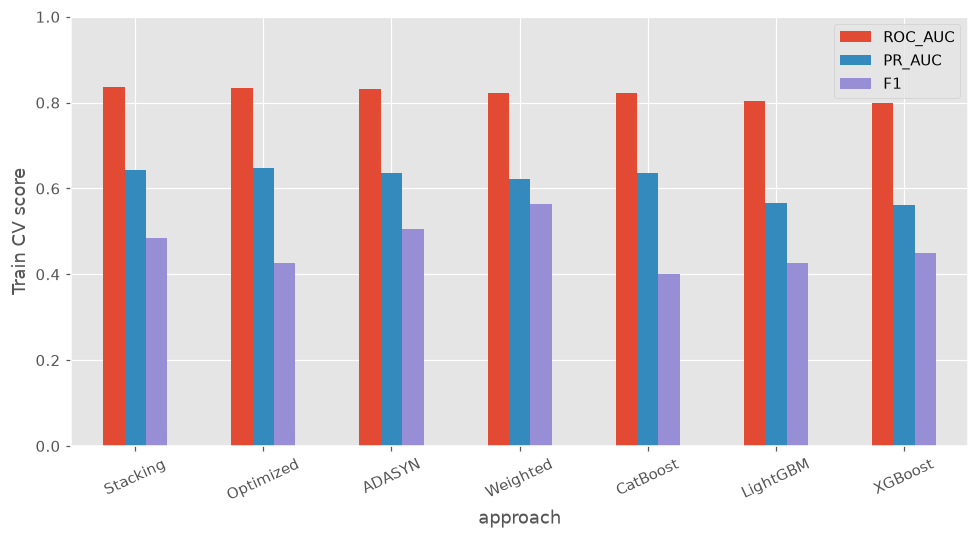

In [6]:
from sklearn.base import BaseEstimator, ClassifierMixin
class FoldWeightedClassifier(ClassifierMixin, BaseEstimator):
    def __init__(self, estimator):
        self.estimator = estimator
    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        ratio = np.sum(np.asarray(y) == 0) / np.sum(np.asarray(y) == 1)
        if isinstance(self.estimator_, CatBoostClassifier):
            self.estimator_.set_params(class_weights=[1., ratio])
        else:
            self.estimator_.set_params(scale_pos_weight=ratio)
        self.estimator_.fit(X, y)
        self.classes_ = self.estimator_.classes_
        return self
    def predict(self, X):
        return self.estimator_.predict(X).ravel()
    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)
stack = StackingClassifier(estimators=[
    ('lightgbm', pipeline(LGBMClassifier(random_state=SEED, n_jobs=2, verbosity=-1))),
    ('forest', pipeline(RandomForestClassifier(random_state=SEED, n_jobs=2))),
    ('svc', pipeline(SVC(probability=True, random_state=SEED)))
], final_estimator=LogisticRegression(random_state=SEED, max_iter=1000), cv=cv, stack_method='predict_proba', n_jobs=1)
evaluate('Stacking', stack)
weighted = ImbPipeline([('preprocess', clone(preprocessor)), ('model', FoldWeightedClassifier(make_model(study.best_params)))])
evaluate('Weighted', weighted)
assert min(y_train.iloc[train_idx].sum() for train_idx, _ in cv.split(X_train, y_train)) > 5
resampled = ImbPipeline([('preprocess', clone(preprocessor)), ('adasyn', ADASYN(random_state=SEED, n_neighbors=5)), ('model', make_model(study.best_params))])
evaluate('ADASYN', resampled)
comparison = pd.DataFrame(rows).set_index('approach').sort_values('ROC_AUC', ascending=False)
display(comparison.round(4))
comparison[['ROC_AUC', 'PR_AUC', 'F1']].plot.bar(ylim=(0, 1), rot=25)
plt.ylabel('Train CV score'); plt.tight_layout(); plt.show()


## Итоговый выбор и единственная тестовая оценка
Критерий заранее задан: максимальный средний ROC-AUC на train CV среди оптимизированного бустинга, стекинга и двух вариантов обработки дисбаланса. Три исходных бустинга служат сравнением. Тестовая строка не участвует в ранжировании; CV и holdout нельзя напрямую интерпретировать как одинаковые оценки.

Выбран по train CV: Stacking


,approach,evaluation,ROC_AUC,PR_AUC,F1
0,Stacking,held-out test (20%),0.8223,0.5774,0.4638


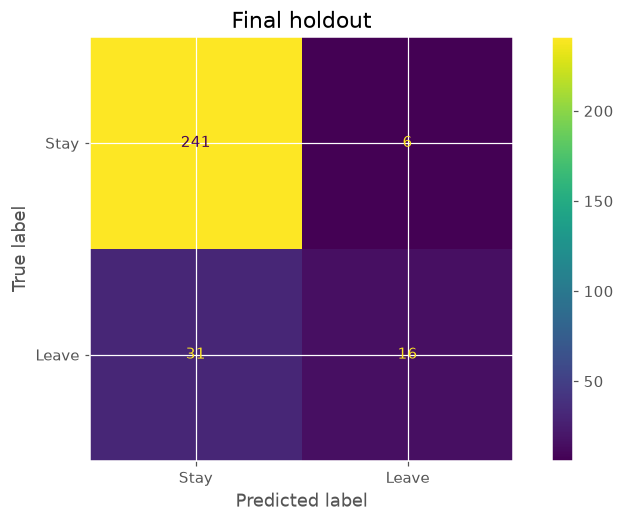

Прирост optimized к лучшему default ROC-AUC: 0.012308092951961336
Изменение PR-AUC / F1 к optimized:


,PR_AUC,F1
approach,,
Weighted,-0.023917,0.136805
ADASYN,-0.010338,0.079447


Лидеры SHAP: StockOptionLevel, OverTime_No, EnvironmentSatisfaction, Age, OverTime_Yes
Лучший train CV ROC-AUC среди подходов: Stacking
Взвешивание изменило F1 на 0.1368 ; ADASYN на 0.0794
Рост F1 не гарантирует роста ранговых ROC-AUC/PR-AUC: сравниваем обе группы метрик.


In [7]:
eligible = ['Optimized', 'Stacking', 'Weighted', 'ADASYN']
final_name = comparison.loc[eligible, 'ROC_AUC'].idxmax()
final_model = clone(candidates[final_name]).fit(X_train, y_train)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_pred = final_model.predict(X_test).ravel()
test_result = pd.DataFrame([{'approach': final_name, 'evaluation': 'held-out test (20%)', 'ROC_AUC': roc_auc_score(y_test, test_proba), 'PR_AUC': average_precision_score(y_test, test_proba), 'F1': f1_score(y_test, test_pred)}])
print('Выбран по train CV:', final_name)
display(test_result.round(4))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=['Stay', 'Leave'])
plt.title('Final holdout'); plt.show()
(ROOT / 'models').mkdir(exist_ok=True)
# Cloudpickle сохраняет также определение пользовательского fold-aware классификатора.
import cloudpickle
with (ROOT / 'models/attrition_model.joblib').open('wb') as stream:
    cloudpickle.dump(final_model, stream)
loaded = joblib.load(ROOT / 'models/attrition_model.joblib')
np.testing.assert_allclose(loaded.predict_proba(X_test), final_model.predict_proba(X_test))
print('Прирост optimized к лучшему default ROC-AUC:', comparison.loc['Optimized', 'ROC_AUC'] - baseline_table['ROC_AUC'].max())
print('Изменение PR-AUC / F1 к optimized:')
display(comparison.loc[['Weighted', 'ADASYN'], ['PR_AUC', 'F1']] - comparison.loc['Optimized', ['PR_AUC', 'F1']])
print('Лидеры SHAP:', ', '.join(importance.head(5).index))
print('Лучший train CV ROC-AUC среди подходов:', final_name)
print('Взвешивание изменило F1 на', round(comparison.loc['Weighted', 'F1'] - comparison.loc['Optimized', 'F1'], 4), '; ADASYN на', round(comparison.loc['ADASYN', 'F1'] - comparison.loc['Optimized', 'F1'], 4))
print('Рост F1 не гарантирует роста ранговых ROC-AUC/PR-AUC: сравниваем обе группы метрик.')


Объяснения отражают ассоциации в этом небольшом учебном наборе. Повторный поиск на других разбиениях может изменить победителя. Подбор порога и внешняя проверка на новых сотрудниках потребовали бы отдельной валидации; holdout для этого повторно не используется.

### Выводы
CatBoost оказался лучшим стандартным бустингом: train CV ROC-AUC 0.8229 против 0.8048 у LightGBM и 0.7997 у XGBoost. Он обучался медленнее, но был выбран по качеству. Optuna повысила ROC-AUC до 0.8352 (+0.0123), при этом уменьшила число деревьев с 1000 до 200.

Стекинг получил максимальный train CV ROC-AUC 0.8376 и был выбран заранее заданным правилом. Его преимущество 0.0024 над настроенным бустингом мало относительно разброса фолдов, поэтому доказанного устойчивого превосходства нет. На независимом test: ROC-AUC 0.8223, PR-AUC 0.5774, F1 0.4638.

Веса повысили train CV F1 с 0.4265 до 0.5633, ADASYN — до 0.5059, но оба снизили ROC-AUC и PR-AUC. Следовательно, выигрыш зависит от выбранной метрики и порога.

Наибольшие SHAP-вклады связаны с StockOptionLevel, переработками, удовлетворённостью средой и возрастом. Большие значения StockOptionLevel и возраста в среднем снижают модельную оценку увольнения; OverTime_Yes повышает её. Это ассоциации в синтетическом наборе IBM, а не причинные эффекты или основание для кадровых решений.

[Интерактивный force plot с полными подписями](../reports/attrition_force.html). Статическая версия оставляет только наиболее крупные подписи; наведите указатель в HTML для отдельных вкладов.